# Tropical Cyclones

Illustrative future tropical-cyclone exposure for the selected site. Historical IBTrACS tracks since 1950 are shifted poleward by the projected migration of tropical-cyclone genesis latitude (+1.13°; Li & Zhou, 2024), and the storms passing within `r1` degrees of the site are compared before and after the shift.

```{glue:figure} tracks_fig
:scale: 50%
:align: center
```

**Figure. Historical (left) and shifted (right) tropical-cyclone tracks near the site**, coloured by Saffir–Simpson category.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Track extraction and plotting come from `functions/tcs.py`, as in the historical notebooks.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from scipy.ndimage import gaussian_filter
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../functions")
from tcs import Extract_Circle, Plot_TCs_HistoricalTracks_Category
from data_downloaders import download_ibtracs
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Poleward shift

The tracks are shifted by **1.13°** of latitude, the projected poleward migration of tropical-cyclone **genesis** latitude over the western North Pacific reported by Li & Zhou (2024):

- **Models:** four CMIP6-HighResMIP atmosphere-only models (CMCC-CM2-VHR4, CNRM-CM6-1-HR, EC-Earth3P-HR, HadGEM3-GC31-HM), with TCs detected by the TRACK and TempestExtremes trackers and a seasonally varying genesis-latitude constraint to remove extratropical storms.
- **Change:** 2020–2050 (SSP5-8.5) minus 1980–2010, for the June–October peak season. The multi-model mean is **+1.13°** with TRACK and +1.16° with TempestExtremes; the annual mean shift is about +1°.
- **Mechanism:** fewer cyclones form south of about 15°N, linked to a weaker, poleward-shifted ascending branch of the regional Hadley circulation.

Caveats for this illustration:

- The shift in the latitude of lifetime maximum intensity is also poleward but smaller and less significant than the genesis shift, so moving whole tracks by the genesis value is an upper-end simplification.
- The value is for the western North Pacific under a high-emission scenario to 2050; applying it southward in the South Pacific assumes a similar response there. The [regional tropical-cyclone projections](../../Regional/tropical_cyclones/tc_highresmip.ipynb) compute the shift in each Pacific subregion with the same models: genesis moves about +0.7 to +1.3° poleward in the peak season across the Pacific, but the whole tracks of the western North Pacific move less (+0.6 to +0.8°), and the projected change in track density is mainly a *decrease* of activity at low latitudes rather than a displacement of the tracks. The 1.13° translation is therefore best read as an upper-end sensitivity test, alongside the projected decrease in the number of TCs (about −7 to −9 % in the western North Pacific).
- Shifting tracks keeps their historical frequency, intensity and shape; projected changes in those (fewer storms overall, a larger share of very intense ones) are not represented.

**Reference:** Li, Z. & Zhou, W. (2024). Poleward migration of tropical cyclones over the western North Pacific in the CMIP6-HighResMIP models constrained by observations. *npj Climate and Atmospheric Science* 7, 161. [doi:10.1038/s41612-024-00704-3](https://doi.org/10.1038/s41612-024-00704-3)


### How large is 1.13° compared with the regional projections?

The table puts the 1.13° in context with the [regional tropical-cyclone projections](../../Regional/tropical_cyclones/tc_highresmip.ipynb), computed with the same CMIP6-HighResMIP models and periods for the Pacific subregion that contains the site (Palau and the Marshall Islands lie in the **Western North Pacific**, 120°E–180°, 0°–40°N). Values are multi-model means for each TC tracker:

- **Li & Zhou (2024)**: the published genesis-latitude shift over the whole western North Pacific, June–October; the source of the 1.13°.
- **Genesis latitude, peak season**: the same quantity recomputed for the site's subregion.
- **Genesis latitude, whole year** and **track latitude, whole year**: the shift of where storms form and of their whole tracks (all points ≥ 34 kt) over the year.
- **Number of TCs**: the projected change in the number of TCs forming in the subregion, which shifting the tracks does not represent.

1.13° is at the **upper end** of these shifts: the tracks as a whole move less than the genesis point, and the main projected change is a decrease in TC activity at low latitudes. The shifted tracks shown below are therefore an upper-end illustration of the poleward migration, not a central estimate. At the site itself, [Tropical cyclones near the site (HighResMIP)](b_tc_highresmip_site.ipynb) counts the model TCs passing within 5°: the models project about −9 to −13 %, while a 1.13° translation of the same models' tracks gives about −27 % (−30 % for IBTrACS); a translation of about 0.5° reproduces the projected change. The table is read from the regional notebook's outputs (`outputs/tables/regional_pacific/PRJ_TC_*`), so that notebook must have been run first.


In [5]:
from tcs import classify_genesis_region

regional_tables = Path("../../../../outputs/tables/regional_pacific")
site_region = classify_genesis_region(site_lon, site_lat)
print(f"{country} lies in the {site_region} subregion")

try:
    mme = lambda name: pd.read_csv(regional_tables / f"PRJ_TC_{name}_highresmip_pacific.csv").query("Model == 'Multi-model mean'")
    lat_change = mme("latitude_change")
    genesis = lambda season: lat_change.query("Latitude == 'Genesis' and Season == @season").set_index("Tracker")[site_region]
    counts = pd.read_csv(regional_tables / "PRJ_TC_count_summary_highresmip_pacific.csv").query("Region == @site_region").set_index("Tracker")
    shift_context = pd.DataFrame({
        "Li & Zhou (2024), WNP genesis latitude, Jun–Oct (°)": {"TRACK": 1.13, "TempestExtremes": 1.16},
        "Genesis latitude, peak season (°)": genesis("Peak season"),
        "Genesis latitude, whole year (°)": genesis("Annual"),
        "Track latitude, whole year (°)": mme("track_latitude_change").set_index("Tracker")[site_region],
        "Number of TCs (%)": counts["Change (%)"],
    }).T.round(2)
    shift_context.columns.name = f"{site_region}: 2020–2050 (SSP5-8.5) vs 1980–2010"
    prj.save_table(shift_context.reset_index(names="Quantity"), tables_dir, "tc_poleward_shift_context", site_tag)
    display(shift_context)
except FileNotFoundError:
    print("Run notebooks/projections/Regional/tropical_cyclones/tc_highresmip.ipynb first to create the regional tables.")


Palau lies in the Western North Pacific subregion


Western North Pacific: 2020–2050 (SSP5-8.5) vs 1980–2010,TRACK,TempestExtremes
"Li & Zhou (2024), WNP genesis latitude, Jun–Oct (°)",1.13,1.16
"Genesis latitude, peak season (°)",0.97,1.13
"Genesis latitude, whole year (°)",0.76,0.94
"Track latitude, whole year (°)",0.59,0.79
Number of TCs (%),-6.60,-9.10


In [6]:
lon_lat = [site_lon % 360, site_lat]
basin = "WP" if site_lat >= 0 else "SP"
r1 = 5  # radius of the circular area in degrees

# Poleward shift of the tracks (degrees of latitude); northward in the northern hemisphere, southward in the southern.
# 1.13° = projected change in WNP TC genesis latitude, JJASO, 1980–2010 to 2020–2050, SSP5-8.5,
# multi-model mean of CMIP6-HighResMIP with the TRACK tracker (Li & Zhou, 2024, npj Clim. Atmos. Sci. 7, 161).
poleward_shift = 1.13
delta_lat = poleward_shift if site_lat >= 0 else -poleward_shift
delta_lon = 0

## IBTrACS

Historical tracks from [IBTrACS](https://www.ncei.noaa.gov/products/international-best-track-archive) cached in `data/tcs/` by the historical tropical-cyclone notebook; they are downloaded if the basin file is missing.

In [7]:
path_data = Path("../../../../data/tcs")
path_data.mkdir(parents=True, exist_ok=True)
tcs_file = path_data / f"tcs_{basin}.nc"

if tcs_file.is_file():
    tcs = xr.load_dataset(tcs_file)
else:
    url = "https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/netcdf/IBTrACS.ALL.v04r01.nc"
    tcs = download_ibtracs(url, basin=basin)
    tcs.to_netcdf(tcs_file)
tcs = tcs.isel(storm=np.where(tcs.isel(date_time=0).time.dt.year >= 1950)[0])

In [8]:
d_vns = {"longitude": "lon", "latitude": "lat", "time": "time", "pressure": "wmo_pres", "wind": "wmo_wind"}

tcs_sel, tcs_sel_params = Extract_Circle(tcs, lon_lat[0], lon_lat[1], r1, d_vns, fillwinds=True)
tcs_sel_params["category"] = (("storm"), np.where(np.isnan(tcs_sel_params.category), -1, tcs_sel_params.category))

tcs_future = tcs.copy()
tcs_future["lat"] = tcs_future["lat"] + delta_lat
tcs_future["lon"] = tcs_future["lon"] + delta_lon
tcs_sel_future, tcs_sel_params_future = Extract_Circle(tcs_future, lon_lat[0], lon_lat[1], r1, d_vns, fillwinds=True)
tcs_sel_params_future["category"] = (("storm"), np.where(np.isnan(tcs_sel_params_future.category), -1, tcs_sel_params_future.category))

print(f"Storms within {r1}° of {site_label}: historical {tcs_sel_params.storm.size}, shifted {tcs_sel_params_future.storm.size}")

Storms within 5° of Palau: historical 531, shifted 414


## Analysis

### Tracks

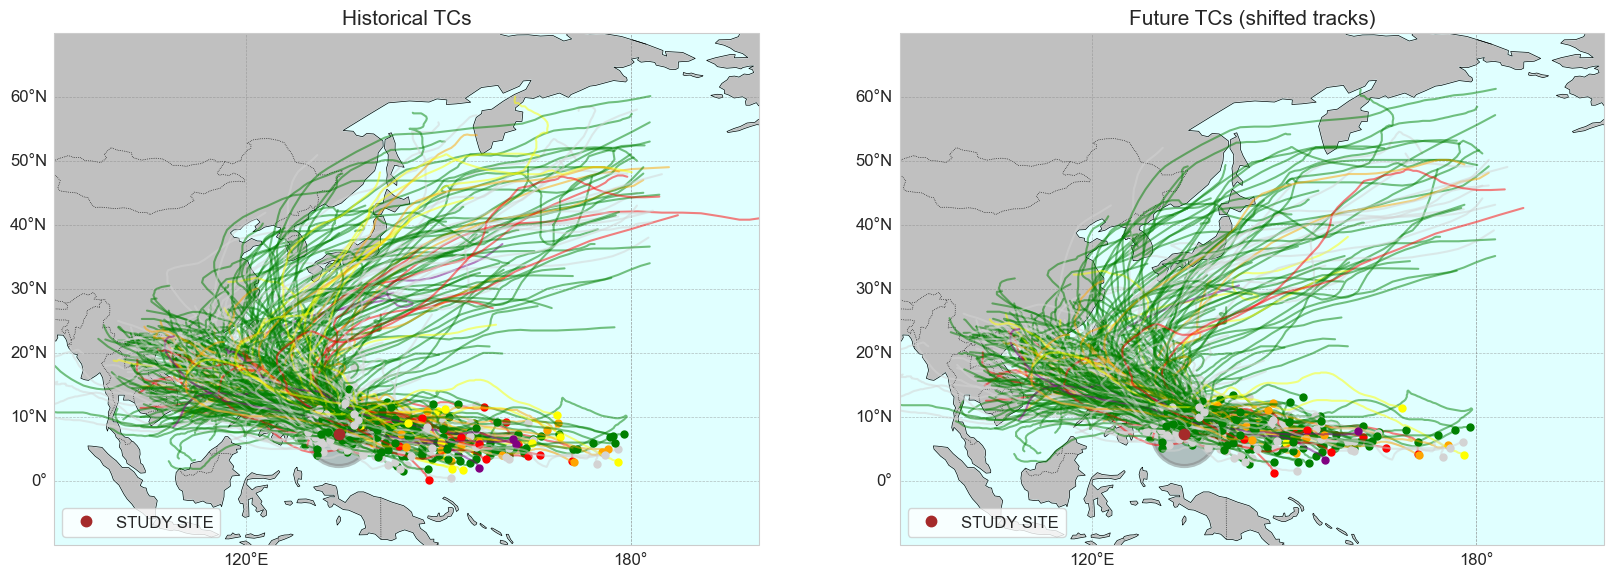

In [9]:
lon1, lon2 = 90, 200
lat1, lat2 = (-10, 70) if site_lat >= 0 else (-50, 10)

fig, axs = plt.subplots(1, 2, figsize=(20, 8), subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
Plot_TCs_HistoricalTracks_Category(tcs_sel, tcs_sel_params.category, lon1, lon2, lat1, lat2,
                                   lon_lat[0], lon_lat[1], r1, ax=axs[0], title="Historical TCs")
Plot_TCs_HistoricalTracks_Category(tcs_sel_future, tcs_sel_params_future.category, lon1, lon2, lat1, lat2,
                                   lon_lat[0], lon_lat[1], r1, ax=axs[1], title="Future TCs (shifted tracks)")
prj.save_figure(fig, fig_dir, "tc_tracks", site_tag)
glue("tracks_fig", fig, display=False)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_tc_tracks_zoom_palau_psw00040309_lat7p337_lon134p477.png')

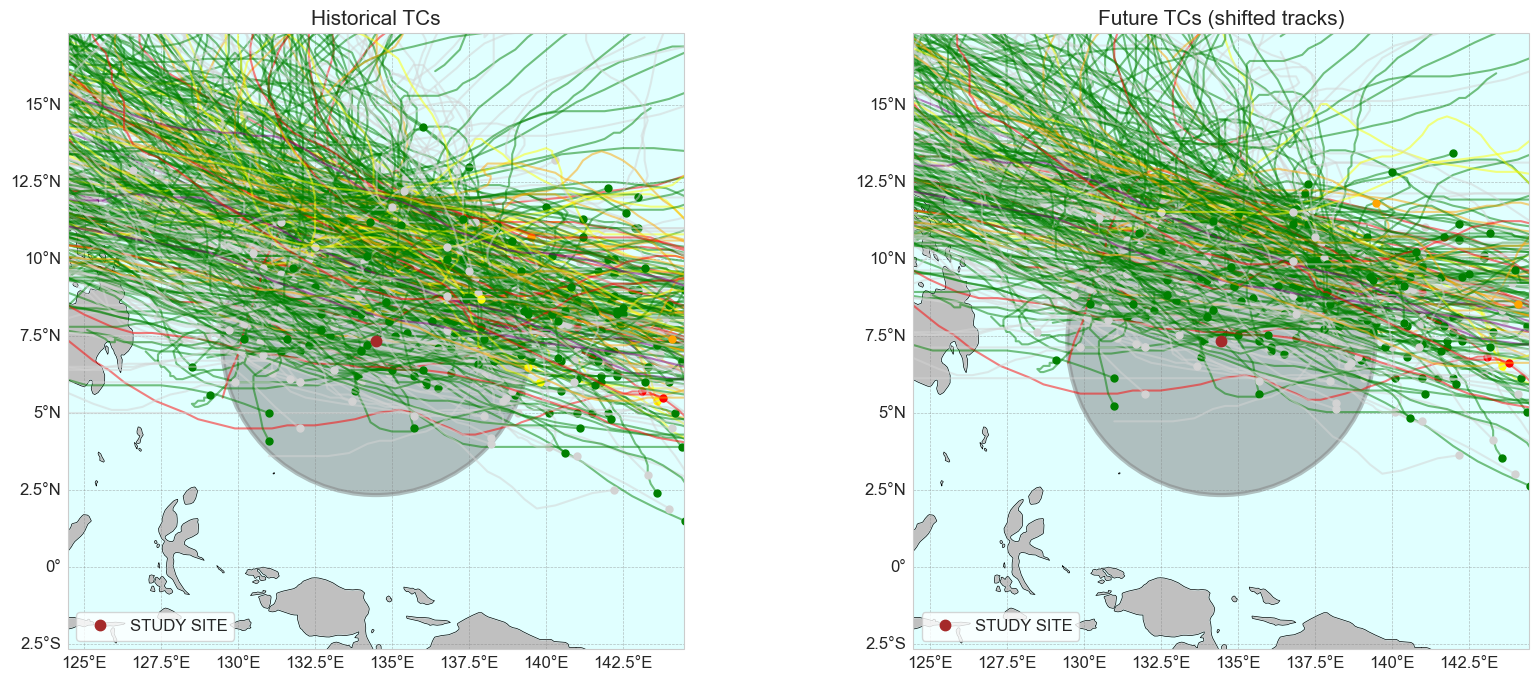

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(20, 8), subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
Plot_TCs_HistoricalTracks_Category(tcs_sel, tcs_sel_params.category, lon1, lon2, lat1, lat2,
                                   lon_lat[0], lon_lat[1], r1, ax=axs[0], title="Historical TCs")
Plot_TCs_HistoricalTracks_Category(tcs_sel_future, tcs_sel_params_future.category, lon1, lon2, lat1, lat2,
                                   lon_lat[0], lon_lat[1], r1, ax=axs[1], title="Future TCs (shifted tracks)")
zoom = 10
for ax in axs:
    ax.set_extent([lon_lat[0] - zoom, lon_lat[0] + zoom, lon_lat[1] - zoom, lon_lat[1] + zoom], crs=ccrs.PlateCarree())
prj.save_figure(fig, fig_dir, "tc_tracks_zoom", site_tag)

### Categories

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_tc_categories_palau_psw00040309_lat7p337_lon134p477.png')

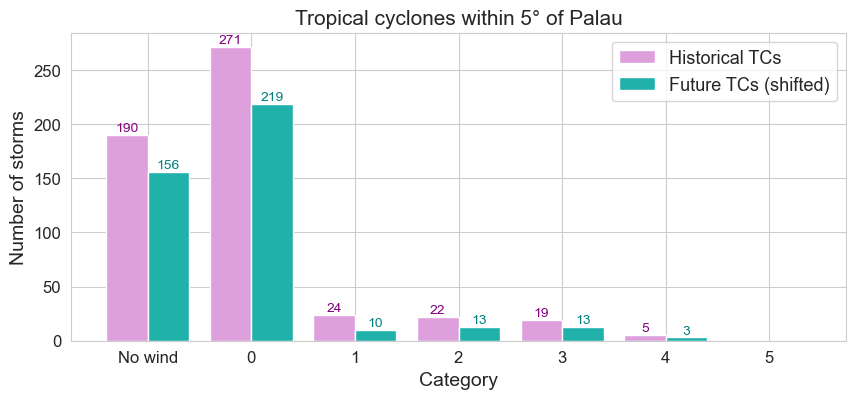

In [11]:
bins = np.arange(-1.5, 6.5, 1)
hist_counts, _ = np.histogram(tcs_sel_params.category.values, bins=bins)
fut_counts, _ = np.histogram(tcs_sel_params_future.category.values, bins=bins)
centres = np.arange(-1, 6)

fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(zorder=-1)
ax.bar(centres - 0.2, hist_counts, width=0.4, color="plum", label="Historical TCs", zorder=2)
ax.bar(centres + 0.2, fut_counts, width=0.4, color="lightseagreen", label="Future TCs (shifted)", zorder=2)
for x, h, f in zip(centres, hist_counts, fut_counts):
    if h > 0:
        ax.text(x - 0.2, h + 0.5, str(h), ha="center", va="bottom", fontsize=10, color="purple")
    if f > 0:
        ax.text(x + 0.2, f + 0.5, str(f), ha="center", va="bottom", fontsize=10, color="teal")
ax.set_xticks(centres, ["No wind"] + [str(c) for c in range(6)])
ax.set(xlabel="Category", ylabel="Number of storms", title=f"Tropical cyclones within {r1}° of {site_label}")
ax.legend()
prj.save_figure(fig, fig_dir, "tc_categories", site_tag)

In [12]:
category_table = pd.DataFrame({"Category": ["No wind"] + [str(c) for c in range(6)],
                               "Historical": hist_counts, "Shifted tracks": fut_counts})
prj.save_table(category_table, tables_dir, "tc_categories", site_tag)
category_table

,Category,Historical,Shifted tracks
0,No wind,190,156
1,0,271,219
2,1,24,10
3,2,22,13
4,3,19,13
5,4,5,3
6,5,0,0


### Track density

Smoothed density of all track points in the basin; contours of the historical (navy) and shifted (dark red) densities are drawn on both panels.

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_tc_density_palau_psw00040309_lat7p337_lon134p477.png')

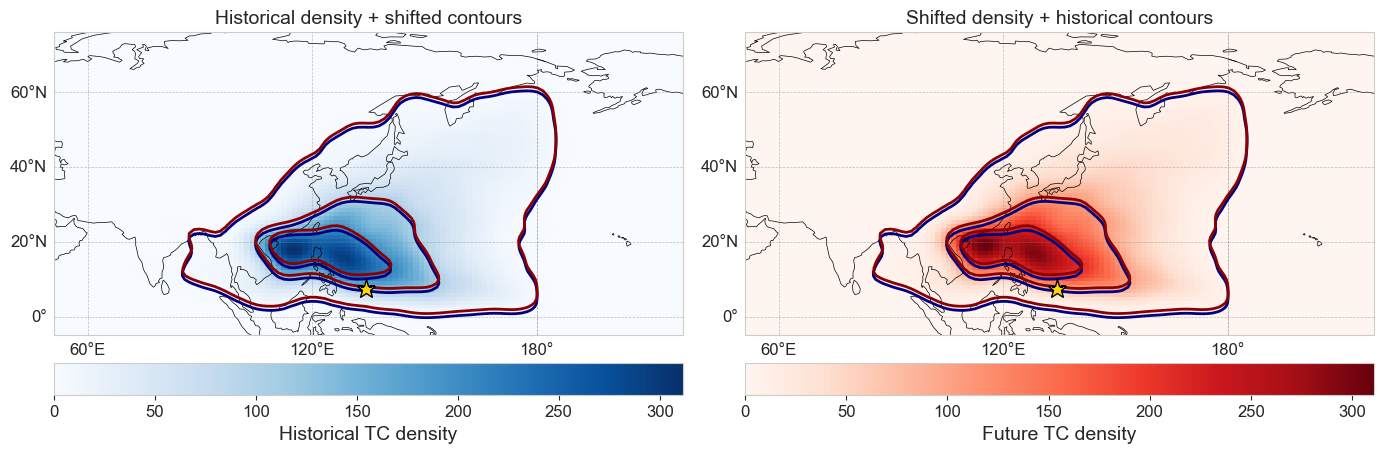

In [13]:
lon_hist, lat_hist = tcs.lon.values.ravel(), tcs.lat.values.ravel()
lon_fut, lat_fut = tcs_future.lon.values.ravel(), tcs_future.lat.values.ravel()
lon_all, lat_all = np.concatenate([lon_hist, lon_fut]), np.concatenate([lat_hist, lat_fut])

pad = 5
extent = [np.nanmin(lon_all) - pad, np.nanmax(lon_all) + pad, np.nanmin(lat_all) - pad, np.nanmax(lat_all) + pad]
lon_bins = np.linspace(extent[0], extent[1], 120)
lat_bins = np.linspace(extent[2], extent[3], 80)
H_hist = gaussian_filter(np.histogram2d(lat_hist, lon_hist, bins=[lat_bins, lon_bins])[0], sigma=2)
H_fut = gaussian_filter(np.histogram2d(lat_fut, lon_fut, bins=[lat_bins, lon_bins])[0], sigma=2)
Lon, Lat = np.meshgrid((lon_bins[:-1] + lon_bins[1:]) / 2, (lat_bins[:-1] + lat_bins[1:]) / 2)
levels_hist = np.linspace(np.percentile(H_hist, 70), H_hist.max(), 4)
levels_fut = np.linspace(np.percentile(H_fut, 70), H_fut.max(), 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
for ax, H, cmap, title, label in [
    (axes[0], H_hist, "Blues", "Historical density + shifted contours", "Historical TC density"),
    (axes[1], H_fut, "Reds", "Shifted density + historical contours", "Future TC density"),
]:
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.LAND, color="silver")
    ax.add_feature(cfeature.OCEAN, color="lightcyan")
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = gl.right_labels = False
    gl.xformatter, gl.yformatter = LongitudeFormatter(), LatitudeFormatter()
    pcm = ax.pcolormesh(Lon, Lat, H, cmap=cmap, shading="auto", transform=ccrs.PlateCarree())
    ax.contour(Lon, Lat, H_hist, levels=levels_hist, colors="navy", linewidths=2, transform=ccrs.PlateCarree())
    ax.contour(Lon, Lat, H_fut, levels=levels_fut, colors="darkred", linewidths=2, transform=ccrs.PlateCarree())
    ax.plot(lon_lat[0], lon_lat[1], "*", color="gold", markersize=14, markeredgecolor="k", transform=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.colorbar(pcm, ax=ax, orientation="horizontal", pad=0.05).set_label(label)
plt.tight_layout()
prj.save_figure(fig, fig_dir, "tc_density", site_tag)